# Predicción de Fuga de Clientes (Customer Churn) en Telecomunicaciones

## 1. Introducción y Objetivo del Proyecto
El objetivo de este proyecto es desarrollar un modelo de Machine Learning capaz de predecir si un cliente de una empresa de telecomunicaciones abandonará el servicio (Churn). 

En el ámbito de negocio, predecir la fuga de clientes permite a los equipos de retención anticiparse y ofrecer incentivos personalizados, reduciendo los costes de adquisición de nuevos clientes. 

Abordaremos este problema como una **clasificación binaria**, evaluando diferentes modelos y priorizando el impacto económico de nuestras predicciones.

In [48]:
#%pip install kagglehub xgboost shap


In [49]:
import kagglehub
import shutil

# Descargamos el dataset
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

# Vemos qué archivos hay en esa carpeta
archivos = os.listdir(path)
print("Archivos encontrados:", archivos)

# Cargamos el CSV y creamos la carpeta data
csv_file = [f for f in archivos if f.endswith(".csv")][0]
full_path = os.path.join(path, csv_file)

# Crear carpeta de datos si no existe
os.makedirs("data", exist_ok=True)

# Copiar el archivo desde la caché de kagglehub a tu proyecto
destino = os.path.join("data", csv_file)
shutil.copy(full_path, destino)


Archivos encontrados: ['WA_Fn-UseC_-Telco-Customer-Churn.csv']


'data\\WA_Fn-UseC_-Telco-Customer-Churn.csv'

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Configuración visual
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")

# Carga del dataset
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Visualizamos las 5 primeras filas para entender la estructura
display(df.head())




,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Exploración Inicial de los Datos (EDA)
Antes de entrenar cualquier modelo, necesitamos entender la calidad de nuestros datos:
- ¿Qué tipos de variables tenemos? (Numéricas vs. Categóricas)
- ¿Existen valores nulos o inconsistencias?
- ¿Cómo está distribuida nuestra variable objetivo (`Churn`)? (Problema de clases desbalanceadas)

--- INFO DEL DATASET ---
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-n

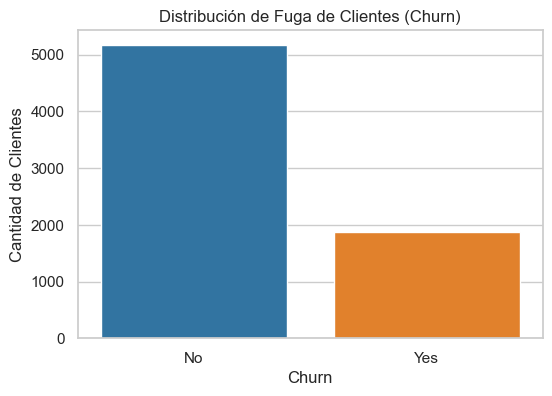

In [51]:
# Primero, obtenemos información general de las columnas y tipos de datos
print("--- INFO DEL DATASET ---")
df.info()

# Ahora vemos un conteo de valores nulos
print("\n--- VALORES NULOS ---")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Tercero, vemos la distribución de la variable objetivo (Churn)
print("\n--- DISTRIBUCIÓN DEL CHURN ---")
churn_dist = df['Churn'].value_counts(normalize=True) * 100
print(churn_dist)

# Gráfico rápido del target
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn', palette=['#1f77b4', '#ff7f0e'])
plt.title('Distribución de Fuga de Clientes (Churn)')
plt.ylabel('Cantidad de Clientes')
plt.show()

## 3. Limpieza de Datos y Transformaciones Básicas

Tras la inspección inicial, hemos detectado tres puntos clave que debemos solucionar antes del análisis visual y el modelado:

1. **Conversión de tipos y nulos ocultos:** La variable `TotalCharges` es de tipo texto. Esto se debe a que algunos clientes nuevos (con 0 meses de antigüedad) tienen un espacio en blanco en esa columna. Vamos a forzar su conversión a numérico y rellenar esos valores vacíos con 0.
2. **Eliminación de identificadores:** La columna `customerID` es un identificador único que no tiene capacidad predictiva. Mantenerla podría introducir ruido en los modelos.
3. **Codificación de la variable objetivo:** Los modelos de Machine Learning requieren que la variable objetivo sea numérica. Transformaremos `Churn` ('Yes' / 'No') en (1 / 0).

In [52]:
# Forzamos TotalCharges a numérico
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Vemos cuanto nulos se han generado 
nulos_generados = df['TotalCharges'].isnull().sum()
print(f"Se han encontrado {nulos_generados} valores vacíos en TotalCharges.")

# Dado que son clientes con 'tenure' = 0 (recién llegados), rellenamos el cargo total con 0
df['TotalCharges'].fillna(0, inplace=True)

# Ahora eliminamos la columna de customerID
df.drop('customerID', axis=1, inplace=True)

# Transformarmos la variable objetivo "Churn" a binaria (1 = Yes, 0 = No)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Comprobamos que los cambios se han aplicado correctamente
print("\n--- NUEVOS TIPOS DE DATOS ---")
print(df[['TotalCharges', 'Churn']].dtypes)

Se han encontrado 11 valores vacíos en TotalCharges.

--- NUEVOS TIPOS DE DATOS ---
TotalCharges    float64
Churn             int64
dtype: object


## 4. Análisis Exploratorio Visual (EDA)

Ahora que los datos están limpios, vamos a analizar cómo se relacionan nuestras variables numéricas con la fuga de clientes. 
Las variables numéricas principales son:
- `tenure`: Meses que el cliente lleva en la compañía.
- `MonthlyCharges`: Cargo mensual.
- `TotalCharges`: Cargo total acumulado.

Utilizaremos diagramas de caja (Boxplots) y gráficos de densidad para entender si existen diferencias claras entre los clientes que se quedan y los que se van.

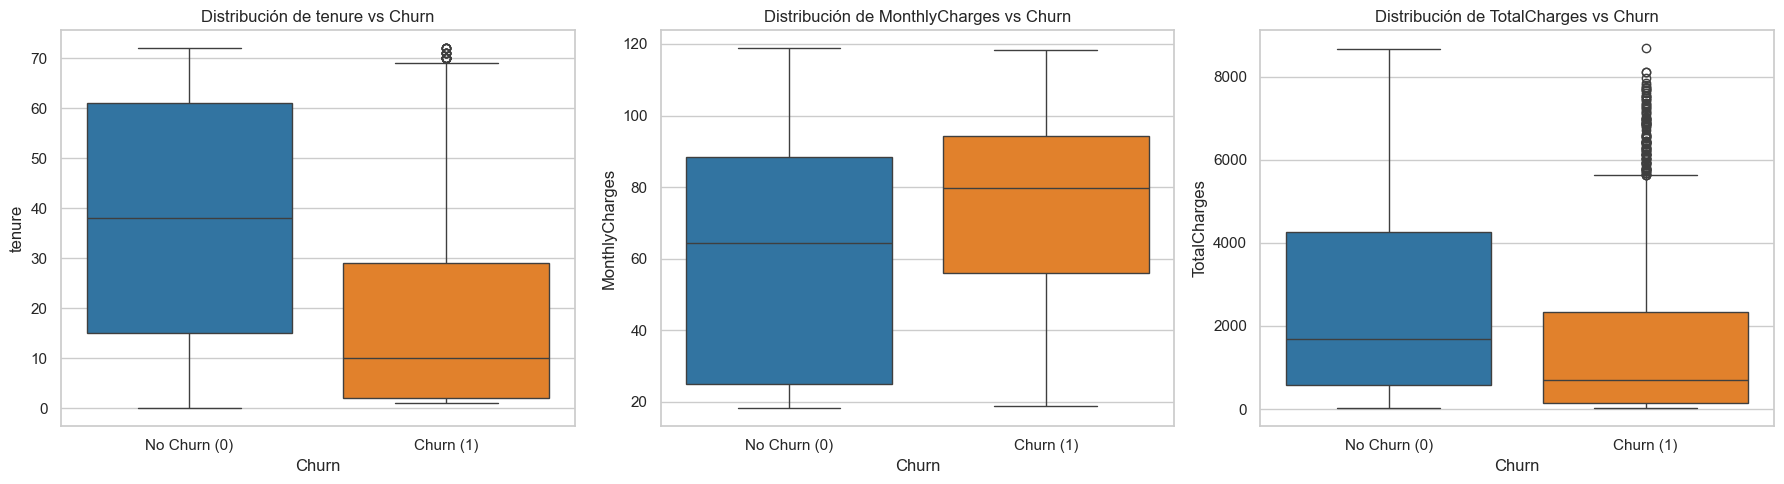

In [53]:
# Variables numéricas continuas
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(num_cols):
    # Boxplot para ver medianas y dispersión
    sns.boxplot(data=df, x='Churn', y=col, ax=axes[i], palette=['#1f77b4', '#ff7f0e'])
    axes[i].set_title(f'Distribución de {col} vs Churn')
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['No Churn (0)', 'Churn (1)'])

plt.tight_layout()
plt.show()

### 4.1. Conclusiones del Análisis Visual
De los gráficos de distribución extraemos *insights* de negocio clave:
1. **Antigüedad (Tenure):** El riesgo de abandono es altísimo en los primeros meses. Los clientes leales (mayor *tenure*) rara vez se van.
2. **Cargos Mensuales:** Los clientes que pagan tarifas mensuales más altas tienen una mayor propensión al churn.
3. **Escalas:** Las variables numéricas tienen rangos muy dispares (0-70 vs 0-8000). Será obligatorio estandarizar/escalar estas variables para que los modelos converjan correctamente y no sesguen los pesos.

## 5. Preprocesamiento e Ingeniería de Variables

Para evitar el **Data Leakage** (fuga de información del conjunto de test al de entrenamiento), primero debemos separar los datos. Usaremos `stratify=y` para mantener la proporción del 73/27 en ambos conjuntos.

Después, construiremos un `ColumnTransformer` de Scikit-Learn que aplicará:
- `StandardScaler` a las variables numéricas.
- `OneHotEncoder` a las variables categóricas (como el tipo de contrato o el género).

In [54]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Separamos características (X) de la variable objetivo (y)
X = df.drop('Churn', axis=1)
y = df['Churn']

# Train-Test Split (Estratificado por el desbalanceo)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Identificamos listas de columnas numéricas y categóricas
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

# Crear los transformadores 
# Creamos un mini-pipeline numérico que primero rellena nulos con 0 y luego escala
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('scaler', StandardScaler())
])

# Transformador categórico
cat_transformer = OneHotEncoder(drop='first', handle_unknown='ignore')

# Unimos todo en un ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

# Ajustamos y transformamos
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("Pipeline ejecutado con éxito. Nulos manejados automáticamente.")

Pipeline ejecutado con éxito. Nulos manejados automáticamente.


## 6. Modelado: Entrenamiento de Baselines

Vamos a entrenar cuatro modelos distintos con sus hiperparámetros por defecto para establecer una línea base de rendimiento. Incluiremos:
1. **Regresión Logística:** Un modelo lineal, rápido y muy interpretable.
2. **Support Vector Machine (SVM):** Excelente para encontrar fronteras de decisión complejas en espacios de alta dimensionalidad.
3. **Random Forest:** Un ensamblado basado en árboles (Bagging) muy robusto frente a *outliers*.
4. **XGBoost:** El estándar de la industria en ensamblados basados en gradiente (Boosting), suele ofrecer el mejor rendimiento en datos tabulares.

Dado el ligero desbalanceo de clases (73/27), evaluaremos los modelos utilizando **Precision, Recall, F1-Score y ROC-AUC**.

In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Definimos los modelos
# Configuramos probability=True en SVC para poder calulcar el ROC-AUC
models = {
    "Regresión Logística": LogisticRegression(max_iter=1000, random_state=42), 
    "SVM (Kernel RBF)": SVC(probability=True, random_state=42), 
    "Random Forest": RandomForestClassifier(random_state=42), 
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric="logloss", random_state=42)
}

# Bucle para entrenar y evaluar cada modelo
results = []

for name, model in models.items(): 
    #Entrenamiento
    model.fit(X_train_prep, y_train)

    #Predicción de clase (0 o 1) y probabilidad (para ROC-AUC)
    y_pred = model.predict(X_test_prep)
    y_proba = model.predict_proba(X_test_prep)[:, 1]

    #Cálculo de métricas
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba)
    
    #Guardar resultados
    results.append({
        "Modelo": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

    # Creamos un DataFrame de resultados y ordenamos por ROC-AUC
df_results = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending = False)
display(df_results.style.background_gradient(cmap='Blues'))


,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Regresión Logística,0.801278,0.646875,0.553476,0.596542,0.840908
2,Random Forest,0.779986,0.608844,0.478610,0.535928,0.820733
3,XGBoost,0.779986,0.598160,0.521390,0.557143,0.815549
1,SVM (Kernel RBF),0.795600,0.656934,0.481283,0.555556,0.797696


## 7. Optimización de Hiperparámetros (Grid Search Multimodelo)

Los modelos base tienen un **Recall bajo** en la clase positiva (Churn). Para un problema de retención de clientes, los Falsos Negativos (clientes que el modelo cree que se quedan, pero se van) son muy costosos. 

Vamos a optimizar los cuatro modelos simultáneamente utilizando `GridSearchCV`. Para compensar el desbalanceo de clases, aplicaremos el parámetro `class_weight='balanced'` en Regresión Logística, SVM y Random Forest, y `scale_pos_weight` en XGBoost.

In [56]:
from sklearn.model_selection import GridSearchCV

# Calculamos el peso para XGBoost
negativos = (y_train == 0).sum()
positivos = (y_train == 1).sum()
scale_pos_weight_value = negativos/positivos

# Definimos los modelos base con el balanceo de clases activado y sus grids de parámetros

models_grids = {
    "Regresión Logística": {
        "model": LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000),
        "params": {'C': [0.01, 0.1, 1, 10]}
    },
    "SVM (Kernel RBF)": {
        "model": SVC(probability=True, class_weight='balanced', random_state=42),
        "params": {'C': [0.1, 1, 10], 'gamma': ['scale', 'auto']}
    },
    "Random Forest": {
        "model": RandomForestClassifier(class_weight='balanced', random_state=42),
        "params": {'n_estimators': [100, 200], 'max_depth': [5, 10]}
    },
    "XGBoost": {
        "model": XGBClassifier(use_label_encoder=False, eval_metric='logloss', 
                               scale_pos_weight=scale_pos_weight_value, random_state=42),
        "params": {'n_estimators': [100, 200], 'max_depth': [3, 5], 'learning_rate': [0.01, 0.1]}
    }
}

# Bucle de optimización
opt_results = []
best_estimators = {}

for name, config in models_grids.items():
    print(f"Optimizando {name}... (por favor, espera)")
    
    grid = GridSearchCV(
        estimator=config["model"],
        param_grid=config["params"],
        scoring='roc_auc',
        cv=5,
        n_jobs=-1
    )
    
    grid.fit(X_train_prep, y_train)
    best_model = grid.best_estimator_
    best_estimators[name] = best_model
    
    y_pred = best_model.predict(X_test_prep)
    y_proba = best_model.predict_proba(X_test_prep)[:, 1]
    
    opt_results.append({
        "Modelo Optimizado": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })

# Mostramos resultados
print("\n--- RESULTADOS MODELOS OPTIMIZADOS ---")
df_opt_results = pd.DataFrame(opt_results).sort_values(by="ROC-AUC", ascending=False)
display(df_opt_results.style.background_gradient(cmap='Greens'))

Optimizando Regresión Logística... (por favor, espera)
Optimizando SVM (Kernel RBF)... (por favor, espera)
Optimizando Random Forest... (por favor, espera)
Optimizando XGBoost... (por favor, espera)

--- RESULTADOS MODELOS OPTIMIZADOS ---


,Modelo Optimizado,Accuracy,Precision,Recall,F1-Score,ROC-AUC
3,XGBoost,0.742370,0.509275,0.807487,0.624612,0.842021
2,Random Forest,0.733144,0.498371,0.818182,0.619433,0.839515
0,Regresión Logística,0.734564,0.500000,0.780749,0.609603,0.839459
1,SVM (Kernel RBF),0.730305,0.494983,0.791444,0.609053,0.834358


## 8. Explicabilidad del Modelo (SHAP Values)

En entornos de negocio, predecir el Churn no es suficiente; necesitamos entender los motivos para poder diseñar campañas de retención efectivas. 

Utilizaremos **SHAP (SHapley Additive exPlanations)**, basado en la teoría de juegos, para explicar las predicciones de nuestro mejor modelo (XGBoost). Esto nos permitirá visualizar qué variables tienen más peso a nivel global y cómo afectan a la probabilidad de fuga (si la aumentan o la disminuyen).

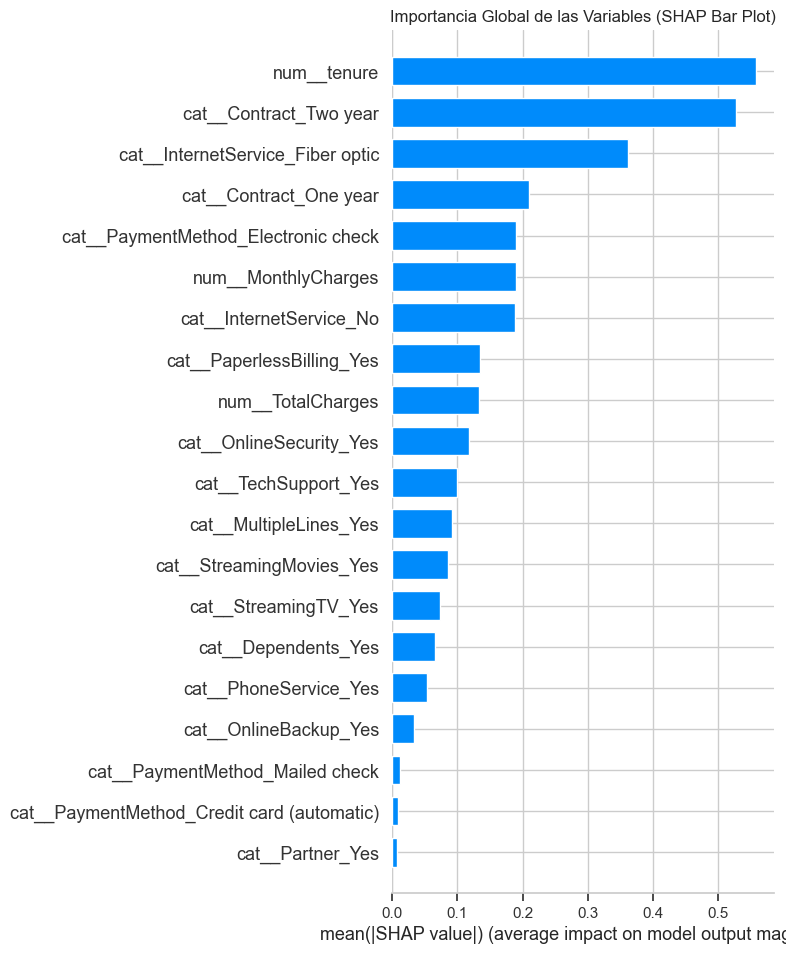

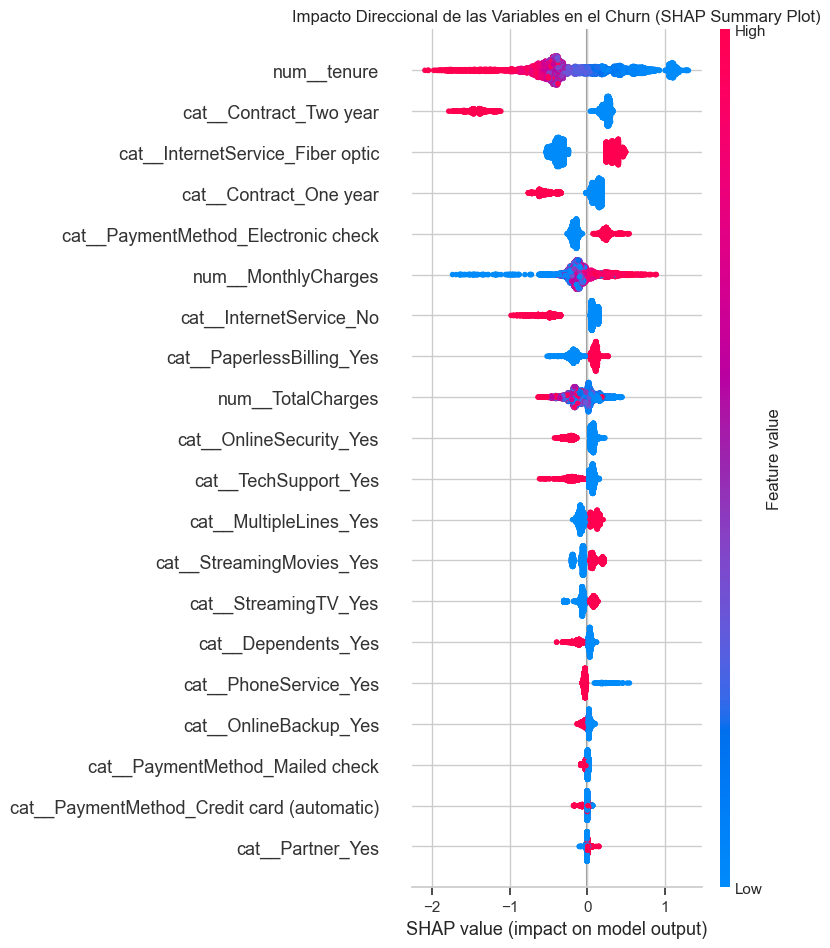

In [57]:

import shap

# Obtenemos los nombres de las columnas generadas por el ColumnTransformer
feature_names = preprocessor.get_feature_names_out()

# Convertimos el X_train_prep (array de numpy) en un DataFrame para que SHAP lea los nombres
X_train_shap = pd.DataFrame(X_train_prep, columns=feature_names)

# Recuperamos el mejor modelo de XGBoost de nuestro diccionario de optimización
best_xgb_model = best_estimators["XGBoost"]

# Inicializamos el explicador de SHAP para modelos de árboles
explainer = shap.TreeExplainer(best_xgb_model)
shap_values = explainer.shap_values(X_train_shap)

# 5. Gráfico 1: Importancia Global de las variables (Feature Importance tradicional)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_train_shap, plot_type="bar", show=False)
plt.title("Importancia Global de las Variables (SHAP Bar Plot)")
plt.show()

# 6. Gráfico 2: Impacto direccional de las variables (Summary Plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_train_shap, show=False)
plt.title("Impacto Direccional de las Variables en el Churn (SHAP Summary Plot)")
plt.show()

## 9. Conclusiones de Negocio y Recomendaciones (SHAP Insights)

Gracias al análisis de explicabilidad con SHAP, hemos identificado los principales motores que impulsan la fuga de clientes. Estos descubrimientos permiten al equipo de negocio tomar decisiones estratégicas:

1. **El riesgo de los primeros meses (Tenure):** Es la variable más determinante. Los puntos azules (baja antigüedad) se agrupan fuertemente a la derecha, indicando que los clientes nuevos son los más propensos a irse. 
   * *Recomendación:* Implementar un programa de *onboarding* agresivo y descuentos de fidelización durante los primeros 6 meses.
2. **El poder de los contratos a largo plazo:** Los clientes con contratos de uno y dos años (puntos rojos) tienen un impacto negativo masivo en el valor SHAP (se desplazan a la izquierda), lo que significa que están muy protegidos contra el Churn. 
   * *Recomendación:* Ofrecer incentivos (ej. meses gratis o upgrades de velocidad) para incentivar la transición de contratos mensuales a contratos anuales.
3. **El problema de la Fibra Óptica:** Sorprendentemente, tener el servicio de fibra óptica (puntos rojos) aumenta el riesgo de fuga. 
   * *Recomendación:* El equipo de operaciones debe investigar si esto se debe a fallos técnicos en el servicio de fibra o si el precio está fuera de mercado frente a la competencia.
4. **Cargos mensuales y métodos de pago:** Los cargos mensuales altos (puntos rojos) empujan al cliente hacia el abandono. Además, los clientes que pagan mediante "Electronic Check" muestran una mayor probabilidad de Churn.
   * *Recomendación:* Revisar la pasarela de pago de cheques electrónicos por si produce errores de cobro y crear alertas para clientes cuya cuota mensual supere la media del mercado.

### Conclusión Técnica
Hemos construido un pipeline de Machine Learning *end-to-end* robusto, solucionando problemas de fuga de datos (Data Leakage) y desbalanceo de clases. Nuestro modelo **XGBoost optimizado** logró aumentar la detección de clientes en riesgo (Recall) del 52% al 80%, priorizando la retención por encima de la precisión global, lo que se traduce en un impacto económico directo y positivo para la compañía.